<h1 style="color:Yellow;">Diabetes Prediction</h1>

<h2 style="color:pink;">Step 1 : Import Dataset</h2>

In [16]:
# Import Libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [4]:
#Importing dataSet
dataset = pd.read_csv("diabetes.csv")
dataset

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


<h2 style="color:pink;">Step 2: Data Inspection </h2>

In [11]:
dataset.info()  #all the information of data

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [9]:
dataset.isnull() # False and True
dataset.isnull().sum() # sum up all the T and F values 0 and 1  

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [12]:
dataset.describe() #mean ,std,min etc

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


<h2 style="color:pink;">Step 3: Data Visualization</h2>

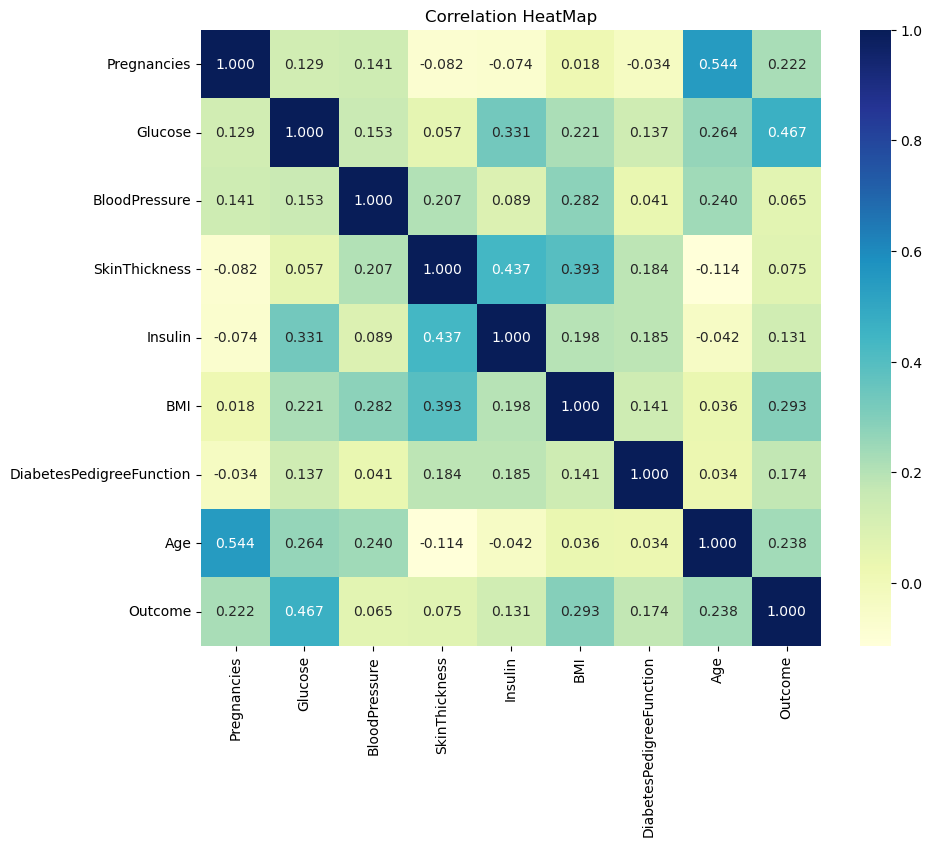

In [28]:
#Correlation plot of independent Variables
plt.figure(figsize = (10,8))
sns.heatmap(dataset.corr(), annot = True, fmt = ".3f", cmap = "YlGnBu")
plt.title("Correlation HeatMap") 
plt.show()
plt.close('all')

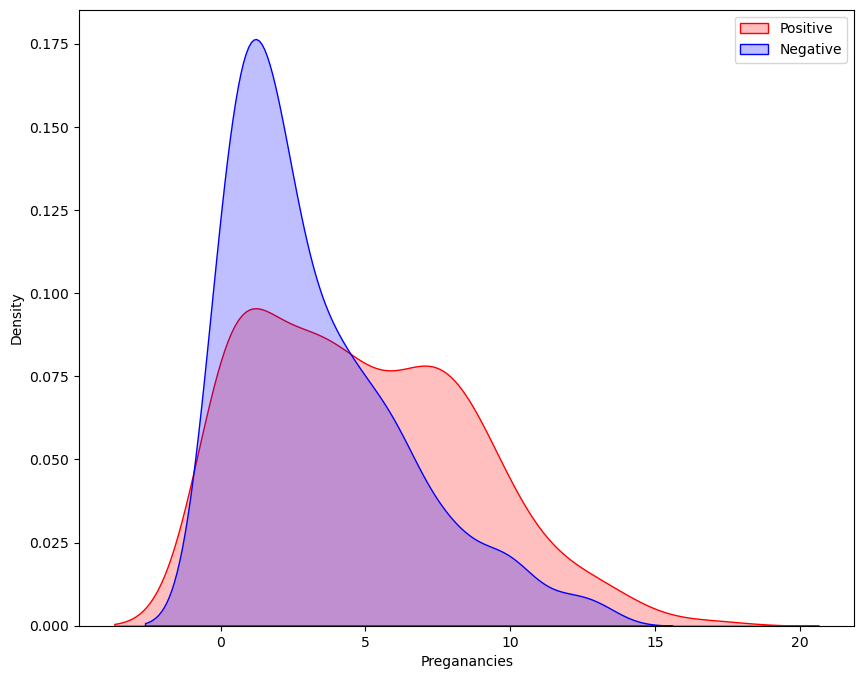

In [31]:
# Exploring Pregnancy and target Varaibles
plt.figure(figsize = (10,8))
# plotting density function graph of the pregnancies and target Variables
kde = sns.kdeplot(dataset["Pregnancies"][dataset["Outcome"] == 1], color = "Red",fill = True)
kde = sns.kdeplot(dataset["Pregnancies"][dataset["Outcome"] == 0], color = "Blue",fill = True)
kde.set_xlabel("Preganancies")
kde.set_ylabel("Density")
kde.legend(["Positive", "Negative"])
plt.show()
plt.close('all')

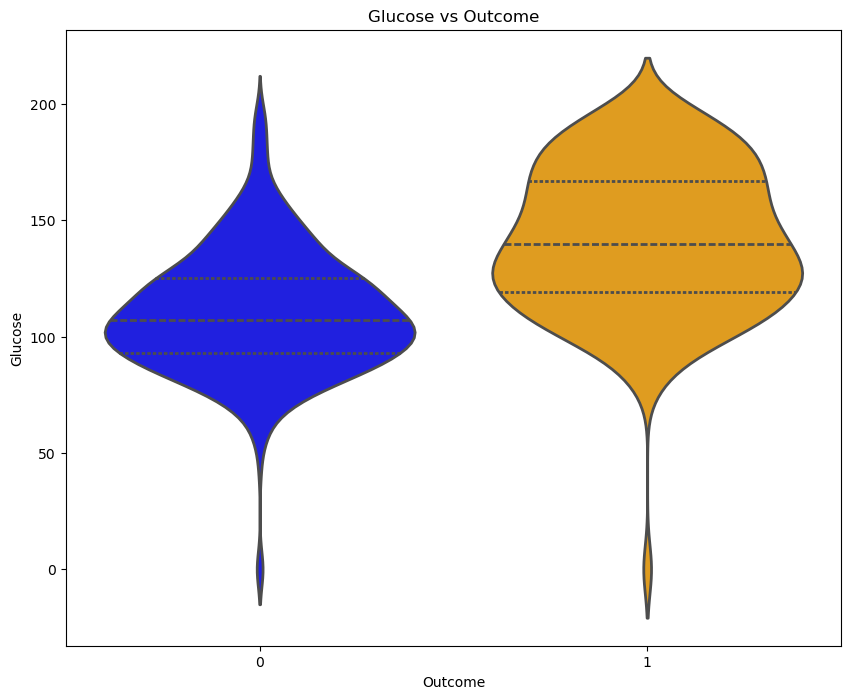

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.close('all')

plt.figure(figsize=(10,8))

sns.violinplot(
    data=dataset,
    x="Outcome",
    y="Glucose",
    hue="Outcome",
    palette=["blue", "orange"],
    linewidth=2,
    inner="quart",
    legend=False
)

plt.title("Glucose vs Outcome")

plt.show()

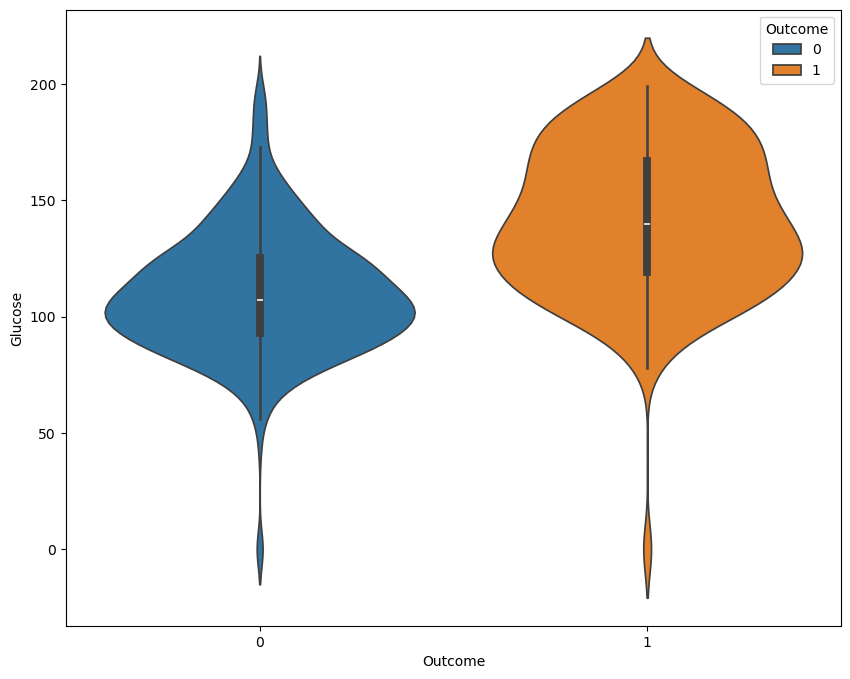

In [34]:
plt.figure(figsize=(10,8))
sns.violinplot(data=dataset, x="Outcome", y="Glucose", hue="Outcome", split=False)
plt.show()

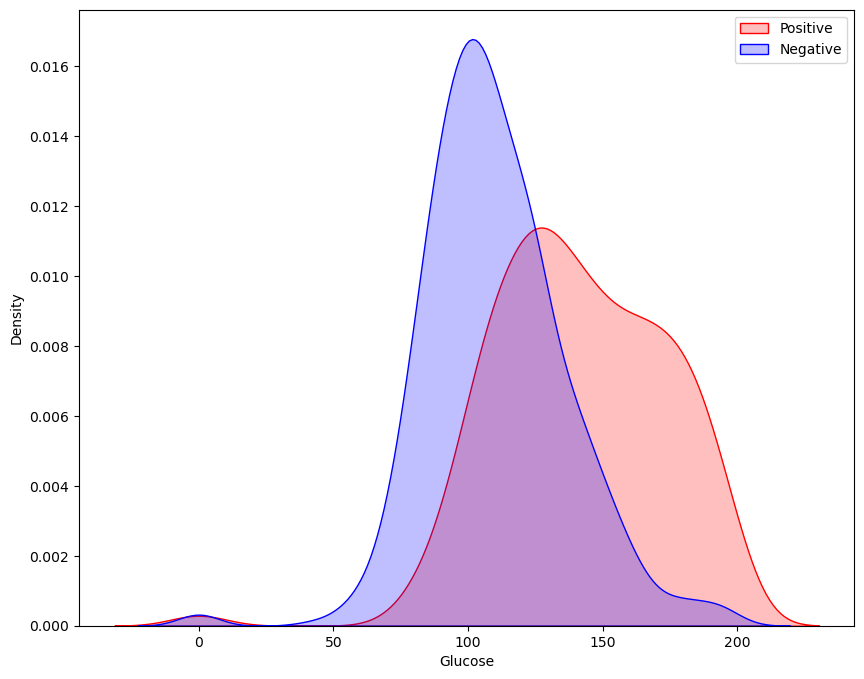

In [35]:
# Exploring Glucose and target Varaibles
plt.figure(figsize = (10,8))
# plotting density function graph of the GLucose and target Variables
kde = sns.kdeplot(dataset["Glucose"][dataset["Outcome"] == 1], color = "Red",fill = True)
kde = sns.kdeplot(dataset["Glucose"][dataset["Outcome"] == 0], color = "Blue",fill = True)
kde.set_xlabel("Glucose")
kde.set_ylabel("Density")
kde.legend(["Positive", "Negative"])
plt.show()
plt.close('all')

In [39]:
# Replce 0 Values with the mean/median of the respectivve feature
# Glucose
dataset["Glucose"] = dataset["Glucose"].replace(0,dataset["Glucose"].median())
# Blood Presure
dataset["BloodPressure"] = dataset["BloodPressure"].replace(0,dataset["BloodPressure"].median())
#BMI
dataset["BMI"] = dataset["BMI"].replace(0,dataset["BMI"].mean())
#Skin Thickness
dataset["SkinThickness"] = dataset["SkinThickness"].replace(0,dataset["SkinThickness"].mean())
#Insulin
dataset["Insulin"] = dataset["Insulin"].replace(0,dataset["Insulin"].mean())

<h2 style="color:pink;">Step 4 :Data Preparation</h2>

In [38]:
dataset

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [42]:
# Splitting the dependent and independent Variable 
x = dataset.drop(["Outcome"], axis = 1)
y = dataset["Outcome"]

In [43]:
x

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35.000000,79.799479,33.6,0.627,50
1,1,85,66,29.000000,79.799479,26.6,0.351,31
2,8,183,64,20.536458,79.799479,23.3,0.672,32
3,1,89,66,23.000000,94.000000,28.1,0.167,21
4,0,137,40,35.000000,168.000000,43.1,2.288,33
...,...,...,...,...,...,...,...,...
763,10,101,76,48.000000,180.000000,32.9,0.171,63
764,2,122,70,27.000000,79.799479,36.8,0.340,27
765,5,121,72,23.000000,112.000000,26.2,0.245,30
766,1,126,60,20.536458,79.799479,30.1,0.349,47


In [44]:
y

0      1
1      0
2      1
3      0
4      1
      ..
763    0
764    0
765    0
766    1
767    0
Name: Outcome, Length: 768, dtype: int64

In [46]:
# Splitting the Dataset into Training and Testing DataSet
from sklearn.model_selection import train_test_split


In [47]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.33,random_state=42)

In [48]:
x_train

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
464,10,115,98,20.536458,79.799479,24.0,1.022,34
223,7,142,60,33.000000,190.000000,28.8,0.687,61
393,4,116,72,12.000000,87.000000,22.1,0.463,37
766,1,126,60,20.536458,79.799479,30.1,0.349,47
570,3,78,70,20.536458,79.799479,32.5,0.270,39
...,...,...,...,...,...,...,...,...
71,5,139,64,35.000000,140.000000,28.6,0.411,26
106,1,96,122,20.536458,79.799479,22.4,0.207,27
270,10,101,86,37.000000,79.799479,45.6,1.136,38
435,0,141,72,20.536458,79.799479,42.4,0.205,29


<h2 style="color:pink;">Step 5: Bulid ML Model</h2>

In [50]:
# KNN
from sklearn.neighbors import KNeighborsClassifier

In [6]:
# Import the required class from scikit-learn
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris  # Example dataset

# Load a sample dataset (you can replace this with your own data)
data = load_iris()
X = data.data
y = data.target

# Split the data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

training_accuracy = []
test_accuracy = []
for n_neighbors in range(1,15):
    # Fixed: removed the extra .n_neighbors - should just be n_neighbors
    knn = KNeighborsClassifier(n_neighbors)
    knn.fit(x_train,y_train)
    # check accuracy score
    training_accuracy.append(knn.score(x_train,y_train))
    # Fixed: corrected typo from test_accurcy to test_accuracy
    test_accuracy.append(knn.score(x_test,y_test))

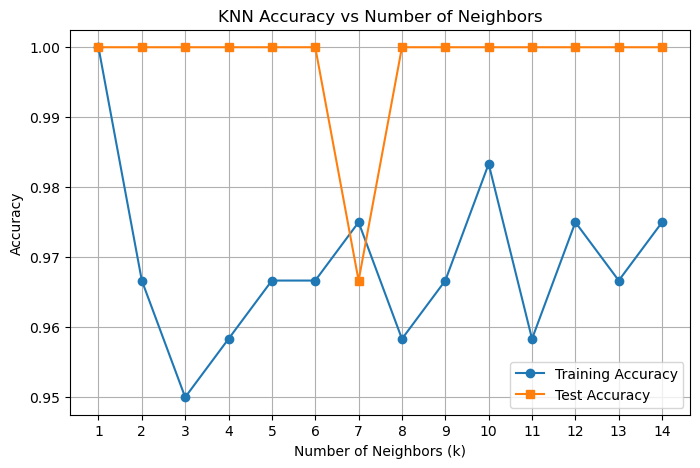

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(range(1,15), training_accuracy, marker='o', label="Training Accuracy")
plt.plot(range(1,15), test_accuracy, marker='s', label="Test Accuracy")

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy vs Number of Neighbors")
plt.xticks(range(1,15))
plt.legend()
plt.grid(True)

plt.show()

<h2 style="color:pink;">Step 6: Training Accuracy and Test Accuracy</h2>

In [7]:
knn = KNeighborsClassifier(n_neighbors=9)
knn.fit(x_train,y_train)
print(knn.score(x_train,y_train), ": Training Accuracy")
print(knn.score(x_test,y_test), " : Test accuracy")

0.9666666666666667 : Training Accuracy
1.0  : Test accuracy


In [11]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(random_state=0)
dt.fit(x_train,y_train)
print(dt.score(x_train,y_train), ": Training Accuracy")
print(dt.score(x_test,y_test), " : Test accuracy")

1.0 : Training Accuracy
1.0  : Test accuracy


In [10]:
dt1 = DecisionTreeClassifier(random_state=0,max_depth=3)
dt1.fit(x_train,y_train)
print(dt1.score(x_train,y_train), ": Training Accuracy")
print(dt1.score(x_test,y_test), " : Test accuracy")

0.9583333333333334 : Training Accuracy
1.0  : Test accuracy


In [15]:
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
# Scale the data
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)
# Train MLP
MLP = MLPClassifier(random_state=42, max_iter=1000)
MLP.fit(x_train_scaled, y_train)
print(MLP.score(x_train_scaled, y_train), ": Training Accuracy")
print(MLP.score(x_test_scaled, y_test), ": Test Accuracy")

0.9833333333333333 : Training Accuracy
1.0 : Test Accuracy


In [13]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
x_train_scaled = sc.fit_transform(x_train)
x_test_scaled = sc.fit_transform(x_test)

In [14]:
from sklearn.neural_network import MLPClassifier

MLP1 = MLPClassifier(
    random_state=42,
    max_iter=1000
)

MLP1.fit(x_train_scaled, y_train)
print(MLP1.score(x_train_scaled, y_train), ": Training Accuracy")
print(MLP1.score(x_test_scaled, y_test), ": Test Accuracy")

0.9833333333333333 : Training Accuracy
0.9333333333333333 : Test Accuracy
